In [47]:
import pandas as pd
import os

train_df = pd.read_csv('../data/raw/train.csv')
test_df = pd.read_csv('../data/raw/test.csv')

print(f"Số dòng trùng lặp: {train_df.duplicated().sum()}")
print(f"Số giá trị thiếu: \n {train_df.isnull().sum()}")

info = {
    "Thuộc tính": ["Số mẫu", "Số đặc trưng", "Cột nhãn", "Số lớp"],
    "Giá trị": [len(train_df), train_df.shape[1], "label", train_df['label'].nunique()]
}
df_info = pd.DataFrame(info)
display(df_info)

Số dòng trùng lặp: 0
Số giá trị thiếu: 
 comment    0
label      0
dtype: int64


,Thuộc tính,Giá trị
0,Số mẫu,11426
1,Số đặc trưng,2
2,Cột nhãn,label
3,Số lớp,3


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23712\4017863960.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=train_df, palette='viridis')


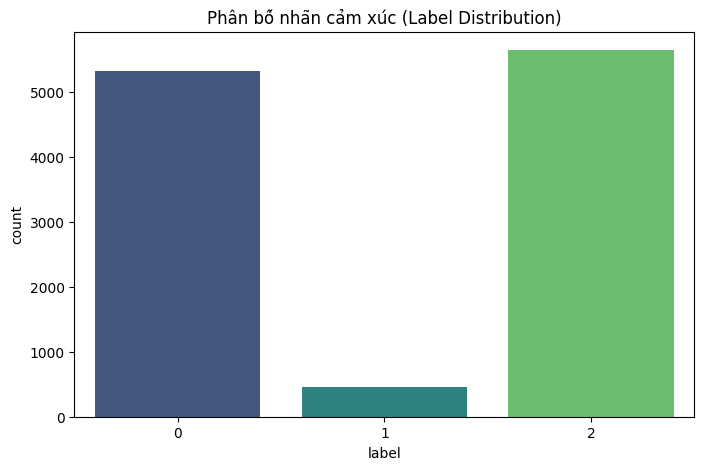

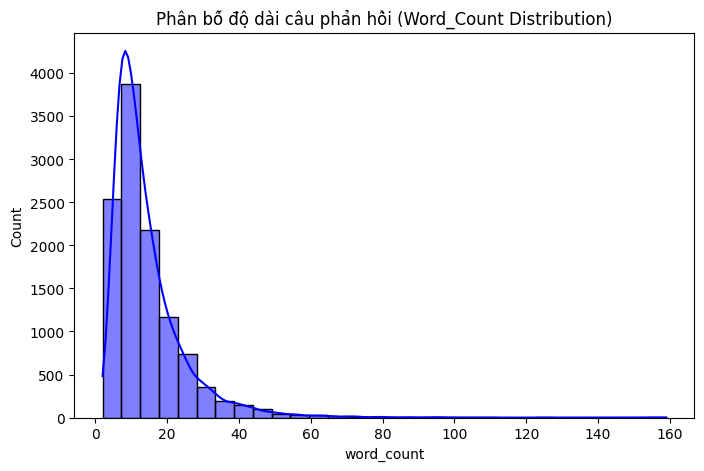

In [48]:
import seaborn as sns 
import matplotlib.pyplot as plt 

#Biểu đồ 1: Phân bố nhãn 
plt.figure(figsize=(8, 5))
sns.countplot(x='label', data=train_df, palette='viridis')
plt.title('Phân bố nhãn cảm xúc (Label Distribution)')
plt.savefig('../results/label_dist.png')
plt.show()

#Biểu đồ 2: Phân bố độ dài câu
train_df['word_count'] = train_df['comment'].apply(lambda x: len(str(x).split()))
plt.figure(figsize=(8, 5))
sns.histplot(train_df['word_count'], bins=30, kde=True, color='blue')
plt.title('Phân bố độ dài câu phản hồi (Word_Count Distribution)')
plt.savefig('../results/word_count.png')
plt.show()

In [49]:
import re
from underthesea import word_tokenize

def clean_text(text):
    text = str(text).lower() 
    text = re.sub(r'[^\w\s]','', text) 
    text = re.sub(r'\b\w*\d\w*\b', '', text)
    text = re.sub(r'\s+',' ', text).strip() 
    return text
# Lọc các dữ liệu rác
train_df['clean_comment'] = train_df['comment'].apply(clean_text)
# Loại các dòng trống khi đã lọc
train_df = train_df[train_df['clean_comment'] != '']
# Xóa các khoảng trắng thừa
train_df['tokenized'] = train_df['clean_comment'].apply(word_tokenize).apply(lambda x: " ".join(x))
# Chọn các cột cần thiết
train_df = train_df[['tokenized', 'label']]
# Lưu dữ liệu
train_df.to_csv('../data/processed/train_cleaned.csv', index=False)
print("Đã quét sạch rác và lưu dữ liệu!")

Đã quét sạch rác và lưu dữ liệu!


KẾT QUẢ BASELINE TUẦN 2: 
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      1409
           1       0.56      0.17      0.26       167
           2       0.92      0.92      0.92      1590

    accuracy                           0.89      3166
   macro avg       0.78      0.68      0.69      3166
weighted avg       0.88      0.89      0.88      3166



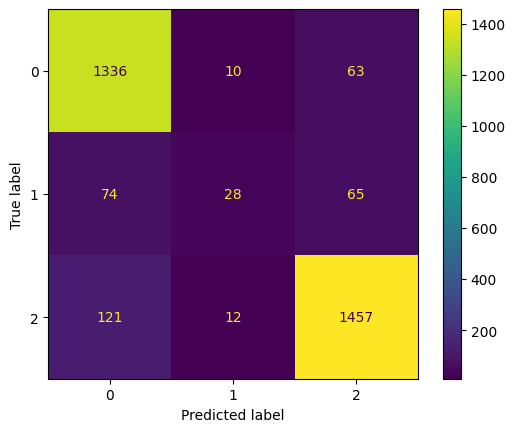

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

#Vector hóa văn bản bằng TF-IDF
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train = tfidf.fit_transform(train_df['tokenized'])
Y_train = train_df['label']

#Train Baseline (SVM)_
baseline_model = LinearSVC()
baseline_model.fit(X_train, Y_train)

#Đọc dữ liệu Test để đánh giá 
test_df = pd.read_csv('../data/raw/test.csv')
#Làm sạch tập Test
X_test = tfidf.transform(test_df['comment'].apply(clean_text))
Y_test = test_df['label']

#Kết quả của các Metric
Y_result = baseline_model.predict(X_test)
print("KẾT QUẢ BASELINE: ")
print(classification_report(Y_test, Y_result))

#Vẽ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(Y_test, Y_result)
plt.savefig('../results/baseline_confusion_matrix.png')
plt.show()
